Training images path: D:\B. Disease Grading\1. Original Images\a. Training Set
Testing images path: D:\B. Disease Grading\1. Original Images\b. Testing Set
Training images count: 413
Testing images count: 103
Total images count: 516

Sample Image Name: IDRiD_001.jpg
Shape: (2848, 4288, 3)
Data type: uint8


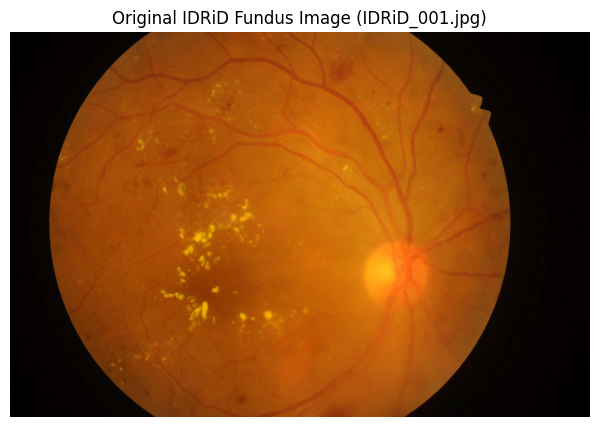

In [1]:
# ==========================================
# CELL 1: Setup Paths & Dependencies
# ==========================================
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from skimage.feature import graycomatrix, graycoprops

# Dataset Root
BASE_DIR = r"D:\B. Disease Grading"

# Exact Image Directories
TRAIN_IMG_DIR = os.path.join(BASE_DIR, "1. Original Images", "a. Training Set")
TEST_IMG_DIR = os.path.join(BASE_DIR, "1. Original Images", "b. Testing Set")

print("Training images path:", TRAIN_IMG_DIR)
print("Testing images path:", TEST_IMG_DIR)

# Get sorted list of images
train_images = sorted(list(Path(TRAIN_IMG_DIR).glob("*.jpg")))
test_images = sorted(list(Path(TEST_IMG_DIR).glob("*.jpg")))

print("Training images count:", len(train_images))
print("Testing images count:", len(test_images))
print("Total images count:", len(train_images) + len(test_images))

# Display one sample image safely
if len(train_images) > 0:
    sample_path = str(train_images[0])
    image_bgr = cv2.imread(sample_path)
    
    if image_bgr is not None:
        image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
        print("\nSample Image Name:", os.path.basename(sample_path))
        print("Shape:", image_rgb.shape)
        print("Data type:", image_rgb.dtype)

        plt.figure(figsize=(8, 5))
        plt.imshow(image_rgb)
        plt.title(f"Original IDRiD Fundus Image ({os.path.basename(sample_path)})")
        plt.axis("off")
        plt.show()
    else:
        print("Warning: Could not read sample image.")

In [2]:
# ==========================================
# CELL 2: Feature Extraction Pipeline
# ==========================================
def preprocess_fundus_image(image_path):
    """Green Channel Extraction, CLAHE, and Denoising."""
    img = cv2.imread(str(image_path))
    if img is None:
        return None
    
    # Extract Green Channel
    green_ch = img[:, :, 1]
    
    # CLAHE
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced_img = clahe.apply(green_ch)
    
    # Median Blur
    denoised_img = cv2.medianBlur(enhanced_img, 3)
    return denoised_img

def extract_features(img_gray):
    """Extract Statistical, Texture (GLCM), and Morphological features."""
    mean_val = np.mean(img_gray)
    std_val = np.std(img_gray)
    var_val = np.var(img_gray)
    
    glcm = graycomatrix(img_gray, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)
    contrast = graycoprops(glcm, 'contrast')[0, 0]
    dissimilarity = graycoprops(glcm, 'dissimilarity')[0, 0]
    homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
    energy = graycoprops(glcm, 'energy')[0, 0]
    correlation = graycoprops(glcm, 'correlation')[0, 0]
    
    _, thresh = cv2.threshold(img_gray, 200, 255, cv2.THRESH_BINARY)
    lesion_area = np.sum(thresh == 255)
    
    return [mean_val, std_val, var_val, contrast, dissimilarity, homogeneity, energy, correlation, lesion_area]

def process_image_set(image_paths):
    records = []
    feature_cols = ['Mean', 'StdDev', 'Variance', 'Contrast', 'Dissimilarity', 'Homogeneity', 'Energy', 'Correlation', 'LesionArea']
    
    for p in image_paths:
        proc_img = preprocess_fundus_image(p)
        if proc_img is not None:
            feats = extract_features(proc_img)
            records.append([os.path.basename(p)] + feats)
            
    return pd.DataFrame(records, columns=['Image_Name'] + feature_cols)

print("Extracting features for Training Set...")
df_train_feats = process_image_set(train_images)

print("Extracting features for Testing Set...")
df_test_feats = process_image_set(test_images)

# Save Extracted Features
train_feat_csv = os.path.join(BASE_DIR, "train_features.csv")
test_feat_csv = os.path.join(BASE_DIR, "test_features.csv")

df_train_feats.to_csv(train_feat_csv, index=False)
df_test_feats.to_csv(test_feat_csv, index=False)

print(f"Saved: {train_feat_csv} ({len(df_train_feats)} rows)")
print(f"Saved: {test_feat_csv} ({len(df_test_feats)} rows)")

Extracting features for Training Set...
Extracting features for Testing Set...
Saved: D:\B. Disease Grading\train_features.csv (413 rows)
Saved: D:\B. Disease Grading\test_features.csv (103 rows)
